# Customer Churn Prediction 
.

## Step 1-2: Load and clean data

In [1]:
import pandas as pd, numpy as np, joblib
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from sqlalchemy import create_engine

DATA, MODELS = Path("../data"), Path("../models")
df = pd.read_csv(DATA / "customer_churn.csv")

# Keep the columns we need and use simple names
df = df.rename(columns={"customerID": "customer_id", "SeniorCitizen": "senior_citizen", "Contract": "contract_type",
                        "InternetService": "internet_service", "TechSupport": "tech_support",
                        "MonthlyCharges": "monthly_charges", "TotalCharges": "total_charges", "Churn": "churn"})
df = df[["customer_id", "gender", "senior_citizen", "tenure", "monthly_charges", "total_charges",
         "contract_type", "internet_service", "tech_support", "churn"]]
print(df.shape); df.head()

(7043, 10)


,customer_id,gender,senior_citizen,tenure,monthly_charges,total_charges,contract_type,internet_service,tech_support,churn
0,7590-VHVEG,Female,0,1,29.85,29.85,Month-to-month,DSL,No,No
1,5575-GNVDE,Male,0,34,56.95,1889.5,One year,DSL,No,No
2,3668-QPYBK,Male,0,2,53.85,108.15,Month-to-month,DSL,No,Yes
3,7795-CFOCW,Male,0,45,42.30,1840.75,One year,DSL,Yes,No
4,9237-HQITU,Female,0,2,70.70,151.65,Month-to-month,Fiber optic,No,Yes


In [2]:
print(df.isnull().sum().sum(), "missing |", df.duplicated().sum(), "duplicates | id unique:", df.customer_id.is_unique)
print(df["churn"].value_counts())
# total_charges is text because 11 rows are blank
df["total_charges"] = pd.to_numeric(df["total_charges"], errors="coerce")
print("Blank total_charges:", df["total_charges"].isna().sum(), "| their tenure:", df.loc[df.total_charges.isna(), "tenure"].unique())

0 missing | 0 duplicates | id unique: True
churn
No     5174
Yes    1869
Name: count, dtype: int64
Blank total_charges: 11 | their tenure: [0]


All 11 blank `total_charges` belong to customers with tenure 0 (not billed yet), so they are filled with 0.

In [3]:
df["total_charges"] = df["total_charges"].fillna(0)
df["senior_citizen"] = df["senior_citizen"].map({0: "No", 1: "Yes"})
assert (df.tenure >= 0).all() and set(df.churn) == {"Yes", "No"}
df.to_csv(DATA / "customer_churn_clean.csv", index=False)
print("Cleaned:", df.shape)

Cleaned: (7043, 10)


## Step 2.3: SQL

In [4]:
engine = create_engine(f"sqlite:///{(DATA / 'churn.db').as_posix()}")
df.to_sql("customers", engine, if_exists="replace", index=False)
for q in [q for q in Path("../sql_analysis.sql").read_text().split(";") if "SELECT" in q]:
    display(pd.read_sql(q, engine))

,total_customers,churned_customers,churn_rate_percentage
0,7043,1869,26.54


,churn,customer_count,average_monthly_charges
0,No,5174,61.27
1,Yes,1869,74.44


,contract_type,customers,churn_rate_pct
0,Month-to-month,3875,42.71
1,One year,1473,11.27
2,Two year,1695,2.83


## Step 3: Basic EDA

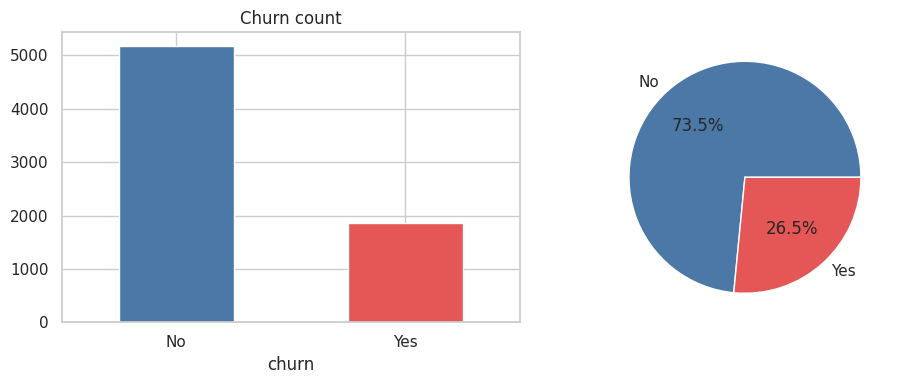

In [5]:
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
df["churn"].value_counts().plot.bar(ax=ax[0], color=["#4C78A8", "#E45756"], rot=0); ax[0].set_title("Churn count")
df["churn"].value_counts().plot.pie(ax=ax[1], autopct="%1.1f%%", colors=["#4C78A8", "#E45756"]); ax[1].set_ylabel("")
plt.tight_layout(); plt.show()

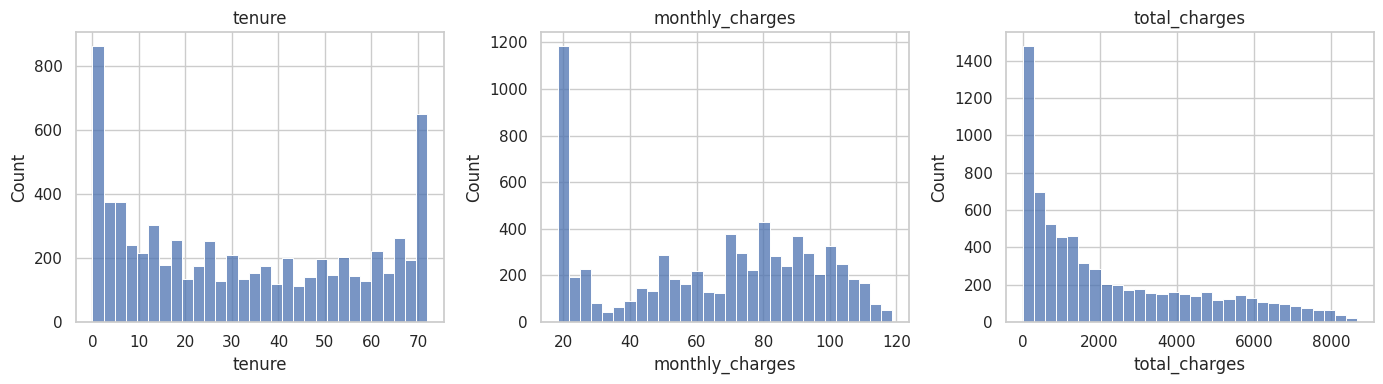

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, c in zip(ax, ["tenure", "monthly_charges", "total_charges"]):
    sns.histplot(df[c], bins=30, ax=a); a.set_title(c)
plt.tight_layout(); plt.show()

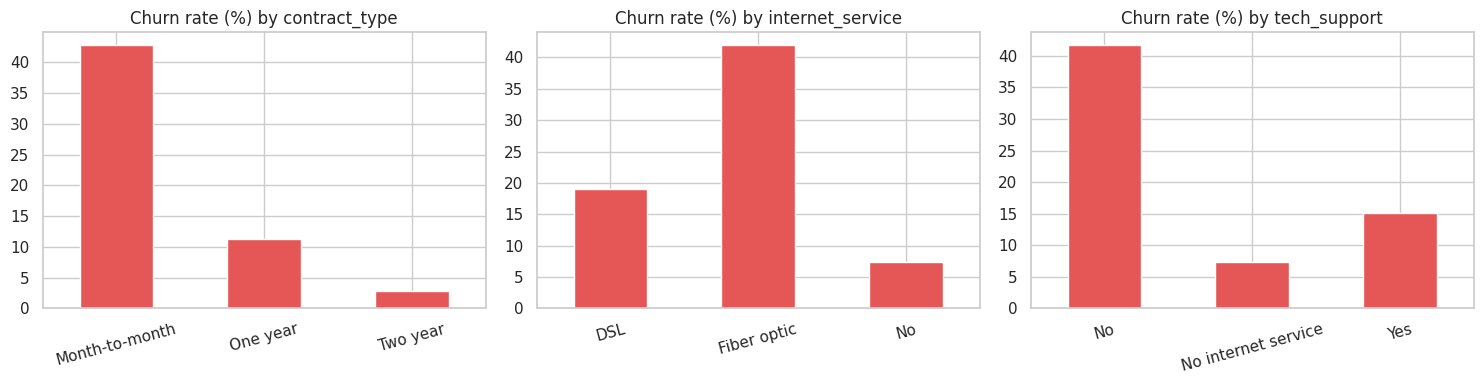

gender
Female    26.9
Male      26.2
Name: churn, dtype: float64


In [7]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, c in zip(ax, ["contract_type", "internet_service", "tech_support"]):
    (df.groupby(c)["churn"].apply(lambda s: (s == "Yes").mean() * 100)).plot.bar(ax=a, color="#E45756", rot=15)
    a.set_title(f"Churn rate (%) by {c}"); a.set_xlabel("")
plt.tight_layout(); plt.show()
print(df.groupby("gender")["churn"].apply(lambda s: round((s == "Yes").mean() * 100, 1)))

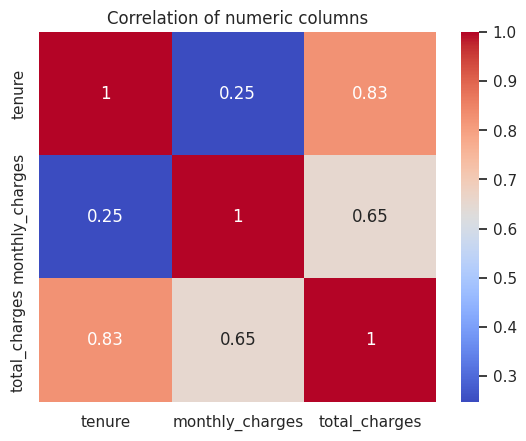

In [8]:
sns.heatmap(df[["tenure", "monthly_charges", "total_charges"]].corr(), annot=True, cmap="coolwarm")
plt.title("Correlation of numeric columns"); plt.show()

**Findings** (associations, not proof of cause):
- About 26.5% of customers churned.
- Month-to-month contracts churn the most (~43%) versus two-year (~3%).
- Fibre-optic customers (~42%) and customers without tech support (~42%) churn more.
- Short-tenure customers churn more; churners also pay more per month on average.
- Gender makes almost no difference.

## Step 4: Prepare data

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

NUMERIC = ["tenure", "monthly_charges", "total_charges"]
CATEGORICAL = ["gender", "senior_citizen", "contract_type", "internet_service", "tech_support"]

X = df[NUMERIC + CATEGORICAL]
y = df["churn"].map({"No": 0, "Yes": 1})
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

# KNN uses distances, so numbers are scaled; categories are one-hot encoded. Fitted on training data only (inside the pipeline).
preprocess = ColumnTransformer([("num", StandardScaler(), NUMERIC),
                                ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL)])
print(X_train.shape, X_test.shape)

(5634, 8) (1409, 8)


## Step 5: Train KNN

In [10]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

pipe = Pipeline([("prep", preprocess), ("knn", KNeighborsClassifier())])
grid = {"knn__n_neighbors": [5, 11, 21, 31, 41, 51, 71], "knn__weights": ["uniform", "distance"]}
search = GridSearchCV(pipe, grid, cv=5, scoring="f1", n_jobs=-1).fit(X_train, y_train)
best_model = search.best_estimator_
print("Best parameters:", search.best_params_, "| CV F1:", round(search.best_score_, 3))

Best parameters: {'knn__n_neighbors': 51, 'knn__weights': 'distance'} | CV F1: 0.568


Accuracy     0.787
Precision    0.617
Recall       0.521
F1-score     0.565
dtype: float64


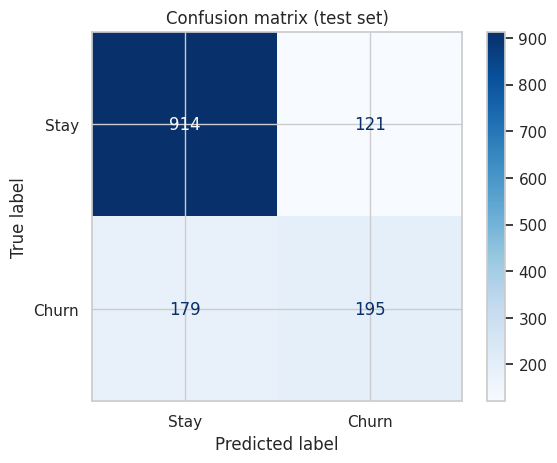

In [11]:
def evaluate(model, X, y):
    pred = model.predict(X)
    return {"Accuracy": accuracy_score(y, pred), "Precision": precision_score(y, pred),
            "Recall": recall_score(y, pred), "F1-score": f1_score(y, pred)}

print(pd.Series(evaluate(best_model, X_test, y_test)).round(3))
ConfusionMatrixDisplay.from_estimator(best_model, X_test, y_test, display_labels=["Stay", "Churn"], cmap="Blues")
plt.title("Confusion matrix (test set)"); plt.show()

**How to read this:** accuracy looks decent, but recall is the share of real churners the model catches, and it is much lower. KNN misses a good number of customers who leave. Precision shows how many flagged customers really churn. These are the real numbers obtained; no target was assumed in advance.

## Step 6: Save the pipeline

In [12]:
joblib.dump(best_model, MODELS / "churn_pipeline.pkl")
loaded = joblib.load(MODELS / "churn_pipeline.pkl")
assert (loaded.predict(X_test) == best_model.predict(X_test)).all()
print("Saved models/churn_pipeline.pkl")

Saved models/churn_pipeline.pkl
